LOADING LIBRARIES

In [ ]:
import os
import json
import rasterio
from rasterio.windows import Window
import geopandas as gpd
from shapely.geometry import box
from tqdm import tqdm

In [ ]:
!pip install torch torchvision pycocotools segmentation-models-pytorch albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.4 MB/s eta 0:00:00


In [ ]:
!pip install torch torchvision torchaudio --extra-index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu118


# **8. MASK R-CNN**

In [ ]:
# checking for building masks
import os

TRAIN_VECTOR_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/vectors"

files = os.listdir(TRAIN_VECTOR_DIR)

print("Vector files:", len(files))
print(files[:5])

Vector files: 145
['tile_000038.gpkg', 'tile_000096.gpkg', 'tile_000154.gpkg', 'tile_000085.gpkg', 'tile_000195.gpkg']


In [ ]:
import os

ROOT = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split"

print(os.listdir(ROOT))

['train', 'val', 'test']


In [ ]:
# ==========================================================
# MASK R-CNN DATASET VALIDATION
# ==========================================================

import geopandas as gpd
import rasterio
import numpy as np
from rasterio.features import rasterize
from shapely.geometry import mapping

# ----------------------------------------------------------
# SAMPLE FILES
# ----------------------------------------------------------

IMAGE_PATH = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/images/tile_000001.tif"

VECTOR_PATH = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/vectors/tile_000001.gpkg"

# ----------------------------------------------------------
# LOAD IMAGE
# ----------------------------------------------------------

with rasterio.open(IMAGE_PATH) as src:

    image = src.read([1,2,3])

    transform = src.transform

    height = src.height
    width = src.width

print("Image Shape:")
print(image.shape)

# ----------------------------------------------------------
# LOAD BUILDINGS
# ----------------------------------------------------------

gdf = gpd.read_file(VECTOR_PATH)

print("\nBuildings:")
print(len(gdf))

# ----------------------------------------------------------
# CREATE INSTANCE MASKS
# ----------------------------------------------------------

masks = []
boxes = []

for geom in gdf.geometry:

    mask = rasterize(
        [(geom, 1)],
        out_shape=(height, width),
        transform=transform,
        fill=0,
        dtype=np.uint8
    )

    if mask.sum() == 0:
        continue

    masks.append(mask)

    xmin, ymin, xmax, ymax = geom.bounds

    boxes.append(
        [xmin, ymin, xmax, ymax]
    )

print("\nInstance Masks:")
print(len(masks))

print("\nBounding Boxes:")
print(len(boxes))

print("\nMask Shape:")
print(masks[0].shape)

Image Shape:
(3, 1024, 1024)

Buildings:
8

Instance Masks:
8

Bounding Boxes:
8

Mask Shape:
(1024, 1024)


In [ ]:
# finding out which tile is the most dense( the most shacks)
import geopandas as gpd
import os

VECTOR_DIR = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/vectors"

max_count = 0
max_file = None

for f in os.listdir(VECTOR_DIR):

    if not f.endswith(".gpkg"):
        continue

    gdf = gpd.read_file(
        os.path.join(VECTOR_DIR, f)
    )

    if len(gdf) > max_count:
        max_count = len(gdf)
        max_file = f

print("Highest building count:")
print(max_count)

print("Tile:")
print(max_file)

Highest building count:
123
Tile:
tile_000123.gpkg


*creating MaskRCNN dataset*

In [ ]:
# ==========================================================
# MASK R-CNN DATASET
# ==========================================================

import os
import torch
import numpy as np
import geopandas as gpd
import rasterio

from torch.utils.data import Dataset
from rasterio.features import rasterize

class MaskRCNNDataset(Dataset):

    def __init__(self, image_dir, vector_dir):

        self.image_dir = image_dir
        self.vector_dir = vector_dir

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.endswith(".tif")
        ])

    def __len__(self):

        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]

        image_path = os.path.join(
            self.image_dir,
            image_name
        )

        vector_path = os.path.join(
            self.vector_dir,
            image_name.replace(".tif", ".gpkg")
        )

        # =====================================
        # IMAGE
        # =====================================

        with rasterio.open(image_path) as src:

            image = src.read([1,2,3])

            transform = src.transform

            height = src.height
            width = src.width

        image = image.astype(np.float32) / 255.0

        # =====================================
        # BUILDINGS
        # =====================================

        gdf = gpd.read_file(vector_path)

        masks_list = [] # Renamed for clarity in internal logic
        boxes_list = [] # Renamed for clarity in internal logic

        for geom in gdf.geometry:

            mask = rasterize(
                [(geom, 1)],
                out_shape=(height, width),
                transform=transform,
                fill=0,
                dtype=np.uint8
            )

            if mask.sum() == 0:
                continue

            masks_list.append(mask)

            rows, cols = np.where(mask > 0)

            xmin = cols.min()
            xmax = cols.max()

            ymin = rows.min()
            ymax = rows.max()

            # Ensure positive height and width
            if xmin == xmax:
                xmax += 1
            if ymin == ymax:
                ymax += 1

            boxes_list.append(
                [xmin, ymin, xmax, ymax]
            )

        # =====================================
        # TORCH FORMAT
        # =====================================

        if len(boxes_list) == 0:
            # No valid objects found for this image
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            masks = torch.zeros((0, height, width), dtype=torch.uint8) # Correct empty 3D tensor
        else:
            boxes = torch.as_tensor(
                boxes_list,
                dtype=torch.float32
            )
            labels = torch.ones(
                (len(boxes_list),),
                dtype=torch.int64
            )
            masks = torch.as_tensor(
                np.array(masks_list), # Convert list to numpy array, then to tensor
                dtype=torch.uint8
            )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        target = {}

        target["boxes"] = boxes
        target["labels"] = labels
        target["masks"] = masks

        target["image_id"] = torch.tensor(
            [idx]
        )

        return image, target

In [ ]:
TRAIN_IMAGES = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/images"
TRAIN_VECTORS = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/train/vectors"

VAL_IMAGES = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/val/images"
VAL_VECTORS = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/val/vectors"

TEST_IMAGES = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/test/images"
TEST_VECTORS = "/content/drive/MyDrive/Image data/Tiles/All Tiles/Dataset_Split/test/vectors"

train_dataset = MaskRCNNDataset(
    TRAIN_IMAGES,
    TRAIN_VECTORS
)

val_dataset = MaskRCNNDataset(
    VAL_IMAGES,
    VAL_VECTORS
)

test_dataset = MaskRCNNDataset(
    TEST_IMAGES,
    TEST_VECTORS
)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 145
Val: 20
Test: 43


*dataset validation*

In [ ]:
image, target = train_dataset[0]

print("Image:")
print(image.shape)

print()

print("Boxes:")
print(target["boxes"].shape)

print()

print("Masks:")
print(target["masks"].shape)

print()

print("Labels:")
print(target["labels"].shape)

Image:
torch.Size([3, 1024, 1024])

Boxes:
torch.Size([8, 4])

Masks:
torch.Size([8, 1024, 1024])

Labels:
torch.Size([8])


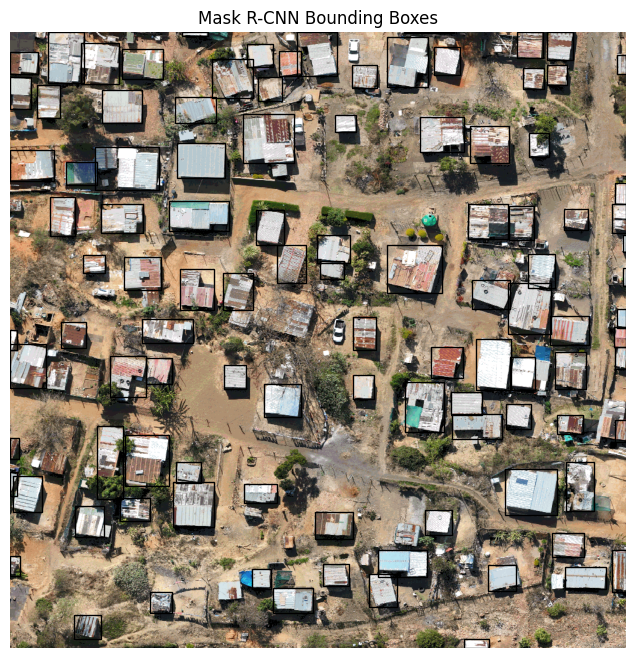

In [ ]:
import matplotlib.pyplot as plt

image, target = train_dataset[122]

img = image.permute(1,2,0).numpy()

plt.figure(figsize=(8,8))
plt.imshow(img)

for box in target["boxes"]:

    xmin, ymin, xmax, ymax = box

    plt.gca().add_patch(
        plt.Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False
        )
    )

plt.title("Mask R-CNN Bounding Boxes")
plt.axis("off")
plt.show()

*creating my dataloaders*

In [ ]:
# ==========================================================
# COLLATE FUNCTION
# ==========================================================

def collate_fn(batch):
    return tuple(zip(*batch))

In [ ]:
# ==========================================================
# DATALOADERS
# ==========================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 73
Val batches: 10
Test batches: 22


In [ ]:
import torch
import torchvision

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(DEVICE)

cuda


In [ ]:
from torchvision.models.detection import maskrcnn_resnet50_fpn

model = maskrcnn_resnet50_fpn(
    weights="DEFAULT"
)

num_classes = 2  # background + building

in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = (
    torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
        in_features,
        num_classes
    )
)

in_features_mask = (
    model.roi_heads.mask_predictor.conv5_mask.in_channels
)

hidden_layer = 256

model.roi_heads.mask_predictor = (
    torchvision.models.detection.mask_rcnn.MaskRCNNPredictor(
        in_features_mask,
        hidden_layer,
        num_classes
    )
)

model = model.to(DEVICE)

print("Mask R-CNN ready")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 170MB/s]


Mask R-CNN ready


In [ ]:
# verifying one forward pass

images, targets = next(iter(train_loader))

images = [
    img.to(DEVICE)
    for img in images
]

targets = [
    {
        k: v.to(DEVICE)
        for k, v in t.items()
    }
    for t in targets
]

model.train()

loss_dict = model(
    images,
    targets
)

print(loss_dict)

print()

print(
    "Total Loss:",
    sum(loss for loss in loss_dict.values()).item()
)

{'loss_classifier': tensor(0.6611, device='cuda:0', grad_fn=<NllLossBackward0>), 'loss_box_reg': tensor(0.6625, device='cuda:0', grad_fn=<DivBackward0>), 'loss_mask': tensor(2.1045, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_objectness': tensor(1.8712, device='cuda:0',
       grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_rpn_box_reg': tensor(0.4595, device='cuda:0', grad_fn=<DivBackward0>)}

Total Loss: 5.758876323699951


In [ ]:
# Adding the metrics functions

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score

import numpy as np

def calculate_maskrcnn_metrics(outputs, targets):

    precisions = []
    recalls = []
    f1s = []
    ious = []

    for output, target in zip(outputs, targets):

        height = target["masks"].shape[-2]
        width = target["masks"].shape[-1]

        gt_mask = np.zeros(
            (height, width),
            dtype=np.uint8
        )

        for m in target["masks"]:

            gt_mask = np.maximum(
                gt_mask,
                m.cpu().numpy()
            )

        pred_mask = np.zeros(
            (height, width),
            dtype=np.uint8
        )

        if len(output["masks"]) > 0:

            masks = (
                output["masks"]
                .detach()
                .cpu()
                .numpy()
            )

            scores = (
                output["scores"]
                .detach()
                .cpu()
                .numpy()
            )

            keep = scores > 0.5

            masks = masks[keep]

            for m in masks:

                pred_mask = np.maximum(
                    pred_mask,
                    (m[0] > 0.5).astype(np.uint8)
                )

        gt_flat = gt_mask.flatten()
        pred_flat = pred_mask.flatten()

        precisions.append(
            precision_score(
                gt_flat,
                pred_flat,
                zero_division=0
            )
        )

        recalls.append(
            recall_score(
                gt_flat,
                pred_flat,
                zero_division=0
            )
        )

        f1s.append(
            f1_score(
                gt_flat,
                pred_flat,
                zero_division=0
            )
        )

        ious.append(
            jaccard_score(
                gt_flat,
                pred_flat,
                zero_division=0
            )
        )

    return (
        np.mean(precisions),
        np.mean(recalls),
        np.mean(f1s),
        np.mean(ious)
    )

In [ ]:

# MASK R-CNN TRAINING settings


import torch
from tqdm import tqdm
import numpy as np
import os

NUM_EPOCHS = 30

PATIENCE = 8

MODEL_DIR = (
    "/content/drive/MyDrive/Image data/MaskRCNN/models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4
)

best_iou = 0

patience_counter = 0

history = []

for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS}"
    )

    # =====================================
    # TRAIN
    # =====================================

    model.train()

    train_losses = []

    for images, targets in tqdm(train_loader):

        images = [
            img.to(DEVICE)
            for img in images
        ]

        targets = [
            {
                k:v.to(DEVICE)
                for k,v in t.items()
            }
            for t in targets
        ]

        loss_dict = model(
            images,
            targets
        )

        loss = sum(
            l for l in loss_dict.values()
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        train_losses.append(
            loss.item()
        )

    train_loss = np.mean(
        train_losses
    )

    # =====================================
    # VALIDATION LOSS
    # =====================================

    model.train()

    val_losses = []

    with torch.no_grad():

        for images, targets in val_loader:

            images = [
                img.to(DEVICE)
                for img in images
            ]

            targets = [
                {
                    k:v.to(DEVICE)
                    for k,v in t.items()
                }
                for t in targets
            ]

            loss_dict = model(
                images,
                targets
            )

            loss = sum(
                l for l in loss_dict.values()
            )

            val_losses.append(
                loss.item()
            )

    val_loss = np.mean(
        val_losses
    )

    # =====================================
    # VALIDATION METRICS
    # =====================================

    model.eval()

    precisions = []
    recalls = []
    f1s = []
    ious = []

    with torch.no_grad():

        for images, targets in val_loader:

            images = [
                img.to(DEVICE)
                for img in images
            ]

            outputs = model(
                images
            )

            p,r,f,i = calculate_maskrcnn_metrics(
                outputs,
                targets
            )

            precisions.append(p)
            recalls.append(r)
            f1s.append(f)
            ious.append(i)

    precision = np.mean(
        precisions
    )

    recall = np.mean(
        recalls
    )

    f1 = np.mean(
        f1s
    )

    iou = np.mean(
        ious
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"Precision: {precision:.4f}"
    )

    print(
        f"Recall: {recall:.4f}"
    )

    print(
        f"F1: {f1:.4f}"
    )

    print(
        f"IoU: {iou:.4f}"
    )

    # =====================================
    # SAVE HISTORY
    # =====================================

    history.append({

        "epoch":
        epoch + 1,

        "train_loss":
        train_loss,

        "val_loss":
        val_loss,

        "precision":
        precision,

        "recall":
        recall,

        "f1":
        f1,

        "iou":
        iou
    })

    # =====================================
    # BEST MODEL
    # =====================================

    if iou > best_iou:

        best_iou = iou

        patience_counter = 0

        torch.save(

            model.state_dict(),

            os.path.join(
                MODEL_DIR,
                "best_maskrcnn.pth"
            )
        )

        print(
            "Best model saved."
        )

    else:

        patience_counter += 1

        print(
            f"No improvement ({patience_counter}/{PATIENCE})"
        )

    # =====================================
    # EARLY STOPPING
    # =====================================

    if patience_counter >= PATIENCE:

        print(
            "\nEarly stopping triggered."
        )

        break


Epoch 1/30


100%|██████████| 73/73 [01:49<00:00,  1.50s/it]


Train Loss: 1.2171
Val Loss: 0.9774
Precision: 0.7545
Recall: 0.9224
F1: 0.8105
IoU: 0.7070
Best model saved.

Epoch 2/30


100%|██████████| 73/73 [02:00<00:00,  1.65s/it]


Train Loss: 0.7782
Val Loss: 0.8627
Precision: 0.7956
Recall: 0.9180
F1: 0.8342
IoU: 0.7396
Best model saved.

Epoch 3/30


...

Train Loss: 0.2082
Val Loss: 0.6074
Precision: 0.8938
Recall: 0.9579
F1: 0.9179
IoU: 0.8582
No improvement (6/8)

Epoch 29/30


100%|██████████| 73/73 [01:52<00:00,  1.55s/it]


Train Loss: 0.2016
Val Loss: 0.5578
Precision: 0.9145
Recall: 0.9560
F1: 0.9307
IoU: 0.8773
No improvement (7/8)

Epoch 30/30


100%|██████████| 73/73 [01:51<00:00,  1.53s/it]


Train Loss: 0.3113
Val Loss: 0.5632
Precision: 0.8109
Recall: 0.9531
F1: 0.8567
IoU: 0.7749
No improvement (8/8)

Early stopping triggered.


In [ ]:
print(len(history))

30


In [ ]:
import pandas as pd

history_df = pd.DataFrame(history)

history_df.head()

,epoch,train_loss,val_loss,precision,recall,f1,iou
0,1,1.217140,0.977366,0.754531,0.922361,0.810467,0.706967
1,2,0.778228,0.862747,0.795595,0.918041,0.834242,0.739580
2,3,0.639181,0.779624,0.787391,0.925524,0.830625,0.736433
3,4,0.560920,0.776004,0.826611,0.907983,0.846796,0.759397
4,5,0.501319,0.726168,0.797251,0.945890,0.846240,0.758898


In [ ]:
# ==========================================================
# SAVE Training HISTORY
# ==========================================================

history_df = pd.DataFrame(history)

csv_path = (
    "/content/drive/MyDrive/Image data/MaskRCNN/history/training_history.csv"
)

history_df.to_csv(
    csv_path,
    index=False
)

print("History saved.")

History saved.


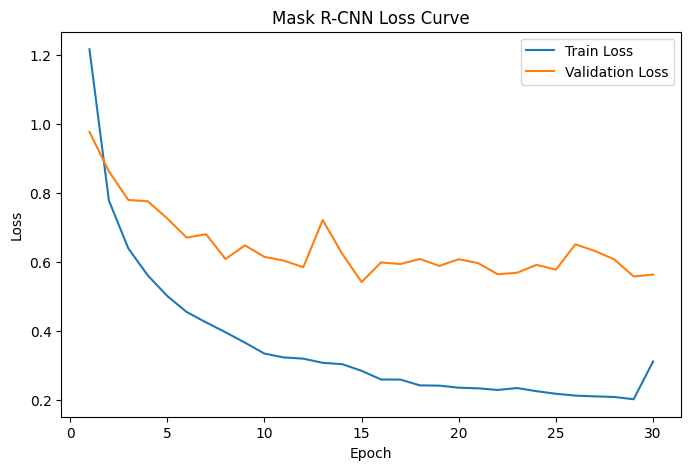

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

plt.figure(figsize=(8,5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Mask R-CNN Loss Curve"
)

plt.legend()

plt.savefig(
    "/content/drive/MyDrive/Image data/MaskRCNN/loss_curve.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
#showing the last epochs

import pandas as pd

df = pd.DataFrame(history)

df.tail(10)

,epoch,train_loss,val_loss,precision,recall,f1,iou
20,21,0.233249,0.596509,0.892647,0.958414,0.917605,0.858958
21,22,0.228577,0.564205,0.921874,0.950886,0.931407,0.878714
22,23,0.234067,0.568540,0.891675,0.956652,0.916725,0.856139
23,24,0.224937,0.591511,0.923834,0.940545,0.927236,0.871720
24,25,0.217427,0.577505,0.885805,0.964132,0.915266,0.855939
25,26,0.212123,0.651060,0.903785,0.958327,0.924701,0.868129
26,27,0.209860,0.631992,0.893497,0.955450,0.917448,0.856745
27,28,0.208162,0.607371,0.893769,0.957852,0.917940,0.858250
28,29,0.201633,0.557837,0.914494,0.955976,0.930738,0.877335
29,30,0.311257,0.563211,0.810910,0.953083,0.856740,0.774889


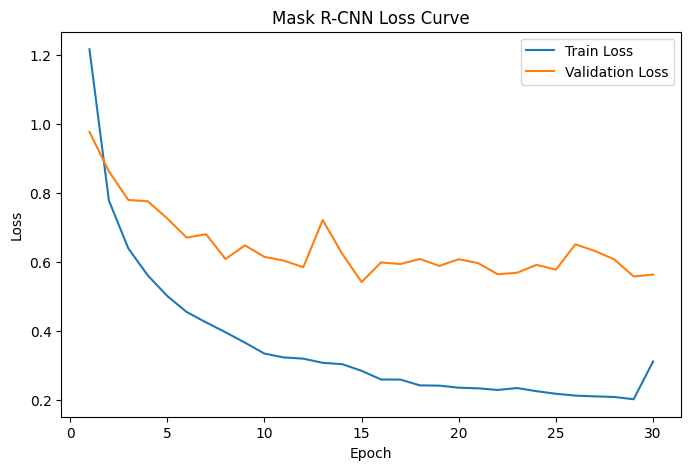

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

plt.figure(figsize=(8,5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Mask R-CNN Loss Curve"
)

plt.legend()

plt.savefig(
    "/content/drive/MyDrive/Image data/MaskRCNN/loss_curve.png",
    bbox_inches="tight"
)

plt.show()

In [ ]:
#LOAD THE BEST MODEL

import torch
import torchvision
from torchvision.models.detection import maskrcnn_resnet50_fpn

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = maskrcnn_resnet50_fpn(
    weights=None
)

num_classes = 2

in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = (
    torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
        in_features,
        num_classes
    )
)

in_features_mask = (
    model.roi_heads.mask_predictor.conv5_mask.in_channels
)

model.roi_heads.mask_predictor = (
    torchvision.models.detection.mask_rcnn.MaskRCNNPredictor(
        in_features_mask,
        256,
        num_classes
    )
)

MODEL_PATH = (
    "/content/drive/MyDrive/Image data/MaskRCNN/models/best_maskrcnn.pth"
)

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=DEVICE
    )
)

model.to(DEVICE)

model.eval()

print("Best model loaded")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 151MB/s]


Best model loaded


In [ ]:
#TEST EVALUATION

import numpy as np
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score

all_gt = []
all_pred = []

with torch.no_grad():

    for images, targets in test_loader:

        images = [
            img.to(DEVICE)
            for img in images
        ]

        outputs = model(images)

        for output, target in zip(outputs, targets):

            height = target["masks"].shape[-2]
            width = target["masks"].shape[-1]

            gt_mask = np.zeros(
                (height, width),
                dtype=np.uint8
            )

            for m in target["masks"]:
                gt_mask = np.maximum(
                    gt_mask,
                    m.numpy()
                )

            pred_mask = np.zeros(
                (height, width),
                dtype=np.uint8
            )

            if len(output["masks"]) > 0:

                masks = (
                    output["masks"]
                    .cpu()
                    .numpy()
                )

                scores = (
                    output["scores"]
                    .cpu()
                    .numpy()
                )

                keep = scores > 0.5

                masks = masks[keep]

                for m in masks:

                    pred_mask = np.maximum(
                        pred_mask,
                        (m[0] > 0.5).astype(np.uint8)
                    )

            all_gt.extend(
                gt_mask.flatten()
            )

            all_pred.extend(
                pred_mask.flatten()
            )

precision = precision_score(
    all_gt,
    all_pred,
    zero_division=0
)

recall = recall_score(
    all_gt,
    all_pred,
    zero_division=0
)

f1 = f1_score(
    all_gt,
    all_pred,
    zero_division=0
)

iou = jaccard_score(
    all_gt,
    all_pred,
    zero_division=0
)

print("\n===== TEST RESULTS =====")

print(
    f"Precision: {precision:.4f}"
)

print(
    f"Recall:    {recall:.4f}"
)

print(
    f"F1 Score:  {f1:.4f}"
)

print(
    f"IoU:       {iou:.4f}"
)


===== TEST RESULTS =====
Precision: 0.9350
Recall:    0.9394
F1 Score:  0.9372
IoU:       0.8818


In [ ]:
# ==========================================================
# SAVE RESULTS
# ==========================================================

results_path = (
    "/content/drive/MyDrive/Image data/MaskRCNN/results/test_results.txt"
)

with open(results_path, "w") as f:

    f.write("Mask RCNN Test Results\n")
    f.write("=======================\n\n")

    f.write(f"Precision: {precision:.4f}\n")
    f.write(f"Recall: {recall:.4f}\n")
    f.write(f"F1 Score: {f1:.4f}\n")
    f.write(f"IoU: {iou:.4f}\n")

print("Results saved.")
print(results_path)

Results saved.
/content/drive/MyDrive/Image data/MaskRCNN/results/test_results.txt


In [ ]:
#Loading my best model

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Image data/MaskRCNN/models/best_maskrcnn.pth",
        map_location=DEVICE
    )
)

model.eval()

print("Best Mask R-CNN loaded")

Best Mask R-CNN loaded


In [ ]:
#Testing tile number 123

In [ ]:
image, target = test_dataset[15]

print(image.shape)

torch.Size([3, 1024, 1024])


In [ ]:
#Prediction

with torch.no_grad():

    prediction = model(
        [image.to(DEVICE)]
    )[0]

In [ ]:
#creating one combined prediction mask

import numpy as np

height = image.shape[1]
width = image.shape[2]

prediction_mask = np.zeros(
    (height, width),
    dtype=np.uint8
)

masks = prediction["masks"].cpu().numpy()
scores = prediction["scores"].cpu().numpy()

keep = scores > 0.5

for m in masks[keep]:

    prediction_mask = np.maximum(
        prediction_mask,
        (m[0] > 0.5).astype(np.uint8)
    )

print(np.unique(prediction_mask))

[0 1]


In [ ]:
#get raster metadata

import rasterio

test_image_name = test_dataset.images[0]

test_image_path = os.path.join(
    TEST_IMAGES,
    test_image_name
)

with rasterio.open(test_image_path) as src:

    profile = src.profile.copy()

    transform = src.transform

In [ ]:
#saving my prediction as GeoTiFF

profile.update(

    dtype=rasterio.uint8,

    count=1,

    compress="lzw"
)

output_tif = (
    "/content/drive/MyDrive/Image data/MaskRCNN/predictions/"
    "maskrcnn_prediction.tif"
)

os.makedirs(
    os.path.dirname(output_tif),
    exist_ok=True
)

with rasterio.open(
    output_tif,
    "w",
    **profile
) as dst:

    dst.write(
        prediction_mask,
        1
    )

print(output_tif)

/content/drive/MyDrive/Image data/MaskRCNN/predictions/maskrcnn_prediction.tif


In [ ]:

# ==========================================================
# MASK R-CNN: SAVE PREDICTION POLYGONS FOR A TEST TILE
# ==========================================================

import os
import torch
import numpy as np
import rasterio
import geopandas as gpd

from rasterio.features import shapes
from shapely.geometry import shape
from shapely.ops import unary_union

# ----------------------------------------------------------
# 1. SELECT A DIFFERENT TEST TILE
# ----------------------------------------------------------

TILE_INDEX = 7  # Change this number to select another tile

image, _ = test_dataset[TILE_INDEX]

image_path = os.path.join(
    test_dataset.image_dir,
    test_dataset.images[TILE_INDEX]
)

# ----------------------------------------------------------
# 2. RUN MASK R-CNN PREDICTION
# ----------------------------------------------------------

model.eval()

with torch.no_grad():
    prediction = model([
        image.to(DEVICE)
    ])[0]

# ----------------------------------------------------------
# 3. FILTER PREDICTIONS BY CONFIDENCE
# ----------------------------------------------------------

SCORE_THRESHOLD = 0.5
MASK_THRESHOLD = 0.5

scores = prediction["scores"].cpu().numpy()
masks = prediction["masks"].cpu().numpy()

# Keep predictions with confidence >= 0.5
keep = scores >= SCORE_THRESHOLD
masks = masks[keep]

# ----------------------------------------------------------
# 4. COMBINE INSTANCE MASKS INTO A BINARY MASK
# ----------------------------------------------------------

if len(masks) > 0:
    pred = np.any(
        masks[:, 0, :, :] >= MASK_THRESHOLD,
        axis=0
    ).astype(np.uint8)
else:
    pred = np.zeros(
        (image.shape[1], image.shape[2]),
        dtype=np.uint8
    )

# ----------------------------------------------------------
# 5. GET THE TILE'S GEOGRAPHIC INFORMATION
# ----------------------------------------------------------

with rasterio.open(image_path) as src:
    transform = src.transform
    crs = src.crs

# ----------------------------------------------------------
# 6. CONVERT BUILDING PIXELS TO POLYGONS
# ----------------------------------------------------------

polygons = []

for geom, value in shapes(
    pred,
    mask=(pred == 1),
    transform=transform
):
    if value == 1:
        polygons.append(shape(geom))

# ----------------------------------------------------------
# 7. SAVE THE OUTPUT AS A GEOPACKAGE
# ----------------------------------------------------------

output_path = f"maskrcnn_prediction_tile_{TILE_INDEX}.gpkg"

gdf = gpd.GeoDataFrame(
    {"class": ["building"] * len(polygons)},
    geometry=polygons,
    crs=crs
)

gdf.to_file(
    output_path,
    driver="GPKG"
)

print("Selected tile:", test_dataset.images[TILE_INDEX])
print("Buildings detected:", len(polygons))
print("Saved to:", output_path)


Selected tile: tile_000029.tif
Buildings detected: 89
Saved to: maskrcnn_prediction_tile_7.gpkg
